# Getting started with the THeatA thermal benchmarks

This notebook compiles, samples and decodes four physical memory experiments, then regenerates their figures from saved results. Run `bash scripts/bootstrap.sh --thermal` from the repository root and select the **THeatA prior calibration** kernel. See the [scientific methods and PBS commands](../docs/thermal_benchmarks.md).

The default runs 768 shots at each point on short grids. Set `PRODUCTION = True` for the full presets, which use 100,000 shots per point. A shot covers the complete three-round memory experiment. Figure panels show the logical error probability and the adjacent-distance ratio with 95% intervals.

In [1]:
from pathlib import Path
import json
import subprocess
import sys

from IPython.display import Image, Markdown, display

REPO = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "configs/thermal_surface_cap.yaml").is_file())
PRODUCTION = True
WORKERS = None if PRODUCTION else 8
RESULTS = REPO / "results" / ("thermal_banch1" if PRODUCTION else "thermal_notebook_smoke")

In [2]:
def cli(*arguments):
    command = [sys.executable, "-m", "theata_prior", "thermal", *map(str, arguments)]
    completed = subprocess.run(command, cwd=REPO, text=True, capture_output=True)
    if completed.stdout:
        print(completed.stdout.strip().replace(f"{REPO}/", ""))
    if completed.stderr:
        print(completed.stderr.strip(), file=sys.stderr)
    completed.check_returncode()


def run_family(family):
    preset = family if PRODUCTION else f"{family}_smoke"
    output = RESULTS / family
    workers = [] if WORKERS is None else ["--workers", str(WORKERS)]
    cli("run", "--config", REPO / f"configs/thermal_{preset}.yaml", "--out", output, "--resume", *workers)
    return output, json.loads((output / "metrics.json").read_text())


def show_figure(output, family):
    display(Image(filename=str(output / "figures" / f"{family}.png"), width=830))


def show_table(rows, columns):
    headers = [label for label, _ in columns]
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines.extend("| " + " | ".join(str(value(row)) for _, value in columns) + " |" for row in rows)
    display(Markdown('\n'.join(lines)))


def format_rate(row):
    return f"{row['logical_error_rate']:.4f} [{row['ci_low']:.4f}, {row['ci_high']:.4f}]"

## Surface code · virtual phonon cap

The Figure 4 profile uses the forward and reverse reused-ancilla circuits and reconstructed-CX noise from the pinned THeatA revision. Each distance reuses one no-cooling trace. The cap only changes the phonon number used for the MS lookup. Cap 0 selects the coldest row at 0.01 quanta.

Built surface d=3 traces/d3/no_cooling
Built surface d=5 traces/d5/no_cooling
Built surface d=7 traces/d7/no_cooling
Built surface d=9 traces/d9/no_cooling
Built surface d=11 traces/d11/no_cooling


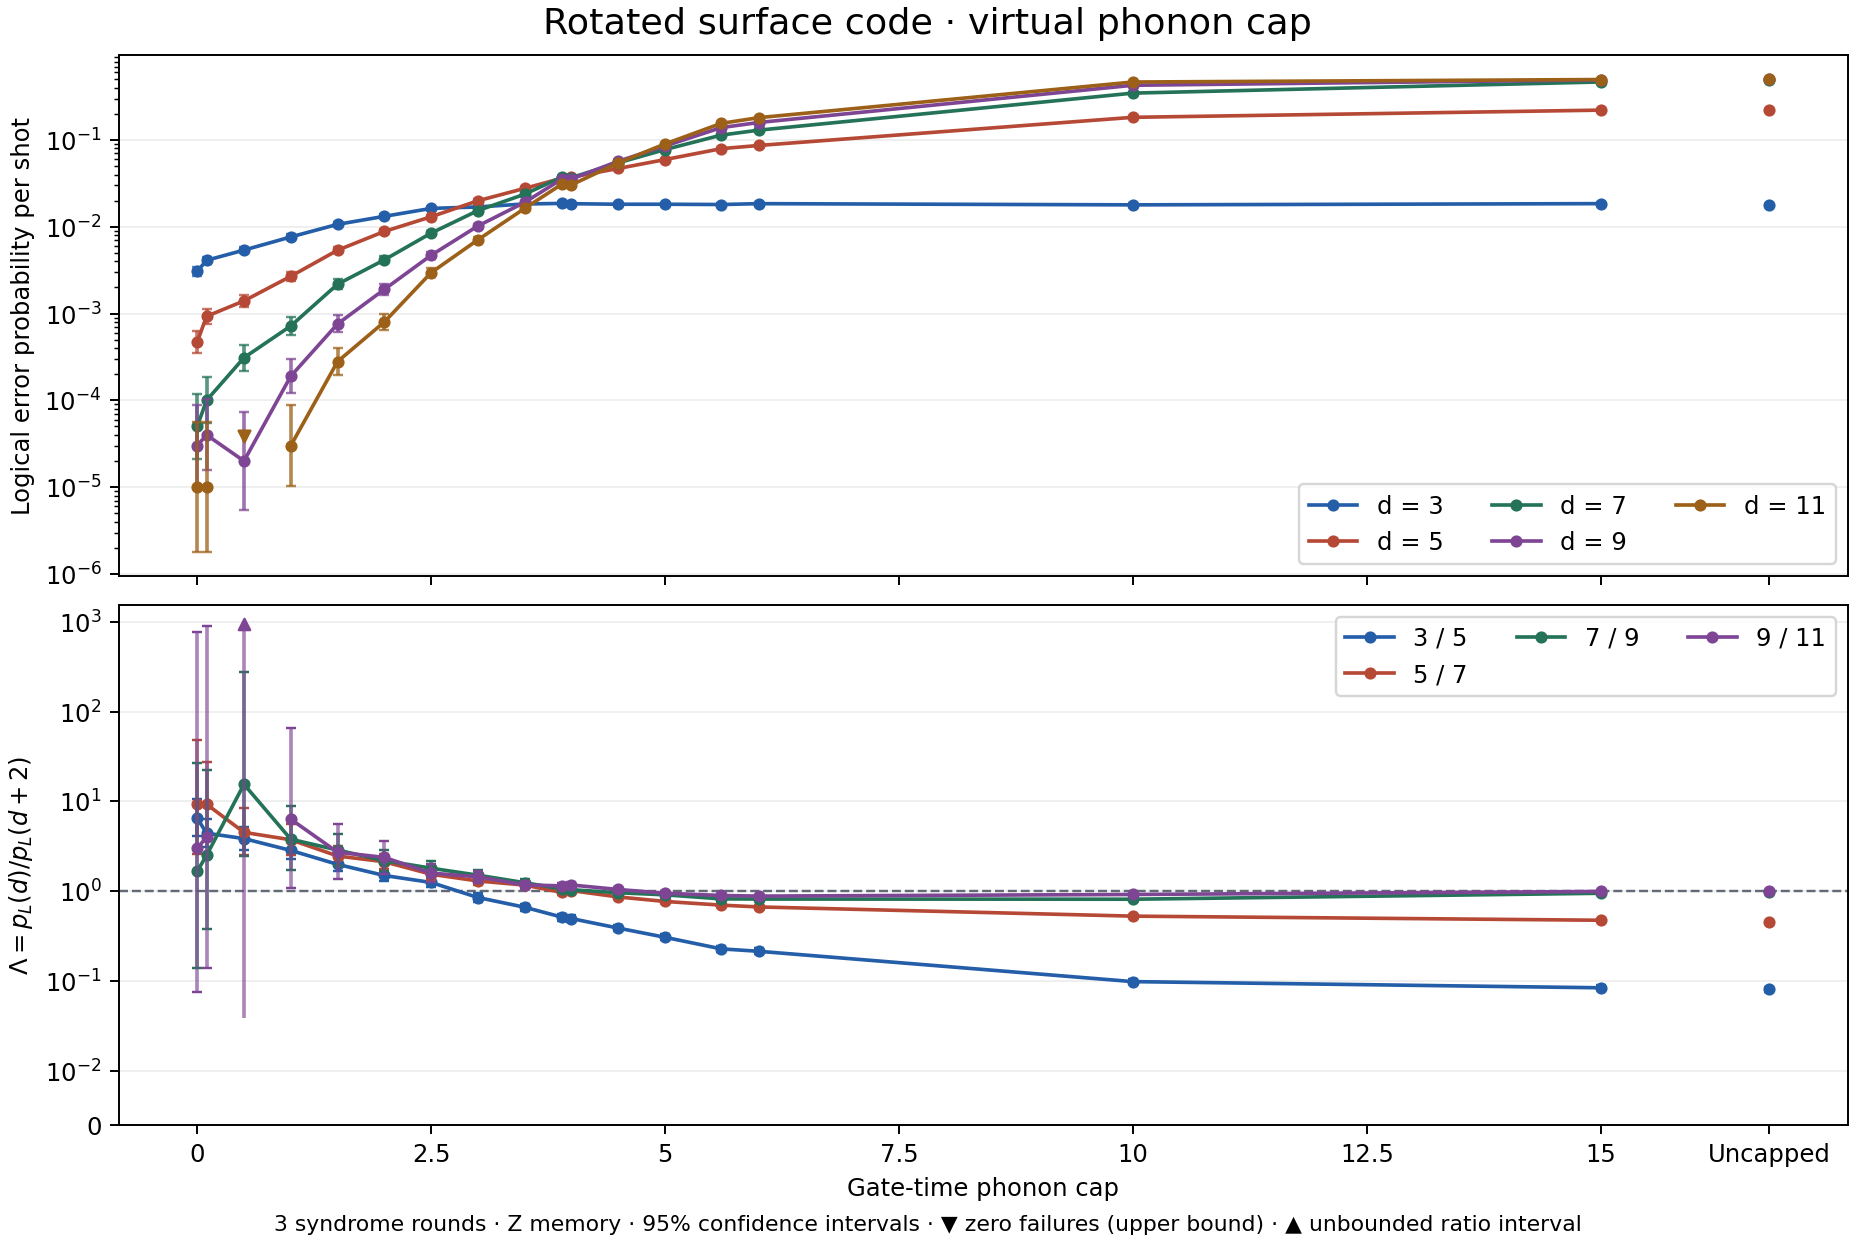

In [13]:
surface_cap, surface_cap_results = run_family("surface_cap")
for distance in sorted({row["distance"] for row in surface_cap_results["rows"]}):
    rows = [row for row in surface_cap_results["rows"] if row["distance"] == distance]
    assert len({row["trace_sha256"] for row in rows}) == 1
show_figure(surface_cap, "surface_cap")

## Surface code · maximum MPT cycles

The Figure 6 profile uses the just-measured ancilla and a 1.5-quanta trigger. The loop limit applies separately at each measurement checkpoint. The table shows how many loops ran and how much cooling and wall time the compiler scheduled.

Built surface d=3 traces/d3/no_cooling
Built surface d=3 traces/d3/mpt/4
Built surface d=3 traces/d3/postmeasure_liz
Built surface d=3 traces/d3/mpt/2
Built surface d=3 traces/d3/mpt/8
Built surface d=3 traces/d3/mpt/1
Built surface d=3 traces/d3/mpt/16
Built surface d=5 traces/d5/no_cooling
Built surface d=5 traces/d5/postmeasure_liz
Built surface d=5 traces/d5/mpt/1
Built surface d=5 traces/d5/mpt/2
Built surface d=5 traces/d5/mpt/4
Built surface d=5 traces/d5/mpt/8
Built surface d=5 traces/d5/mpt/16
Built surface d=7 traces/d7/no_cooling
Built surface d=7 traces/d7/postmeasure_liz
Built surface d=7 traces/d7/mpt/1
Built surface d=7 traces/d7/mpt/2
Built surface d=7 traces/d7/mpt/4
Built surface d=7 traces/d7/mpt/8
Built surface d=7 traces/d7/mpt/16


| Distance | Condition | MPT iterations | CoolOps | Wall time (ms) | Logical error [95% CI] |
| --- | --- | --- | --- | --- | --- |
| 3 | no_cooling | 0 | 0 | 84.1 | 0.0187 [0.0179, 0.0196] |
| 3 | postmeasure_liz | 0 | 24 | 105.8 | 0.0107 [0.0101, 0.0113] |
| 3 | mpt_1 | 12 | 57 | 149.4 | 0.0097 [0.0091, 0.0103] |
| 3 | mpt_2 | 23 | 72 | 174.3 | 0.0090 [0.0084, 0.0096] |
| 3 | mpt_4 | 37 | 88 | 200.7 | 0.0085 [0.0080, 0.0091] |
| 3 | mpt_8 | 49 | 99 | 218.4 | 0.0087 [0.0081, 0.0093] |
| 3 | mpt_16 | 52 | 102 | 223.3 | 0.0083 [0.0077, 0.0089] |
| 5 | no_cooling | 0 | 0 | 366.7 | 0.2187 [0.2161, 0.2213] |
| 5 | postmeasure_liz | 0 | 72 | 432.3 | 0.0803 [0.0786, 0.0820] |
| 5 | mpt_1 | 57 | 239 | 658.4 | 0.0407 [0.0395, 0.0420] |
| 5 | mpt_2 | 114 | 349 | 836.1 | 0.0238 [0.0229, 0.0247] |
| 5 | mpt_4 | 228 | 567 | 1188.2 | 0.0115 [0.0108, 0.0122] |
| 5 | mpt_8 | 454 | 992 | 1874.7 | 0.0074 [0.0069, 0.0080] |
| 5 | mpt_16 | 881 | 1663 | 2959.7 | 0.0057 [0.0053, 0.0062] |
| 7 | no_cooling | 0 | 0 | 1135.0 | 0.4916 [0.4885, 0.4947] |
| 7 | postmeasure_liz | 0 | 144 | 1265.7 | 0.4761 [0.4730, 0.4792] |
| 7 | mpt_1 | 129 | 523 | 1778.7 | 0.4158 [0.4127, 0.4188] |
| 7 | mpt_2 | 258 | 773 | 2180.9 | 0.3062 [0.3034, 0.3091] |
| 7 | mpt_4 | 516 | 1273 | 2985.2 | 0.1382 [0.1361, 0.1404] |
| 7 | mpt_8 | 1032 | 2273 | 4593.8 | 0.0408 [0.0396, 0.0420] |
| 7 | mpt_16 | 2064 | 4273 | 7810.9 | 0.0148 [0.0141, 0.0156] |

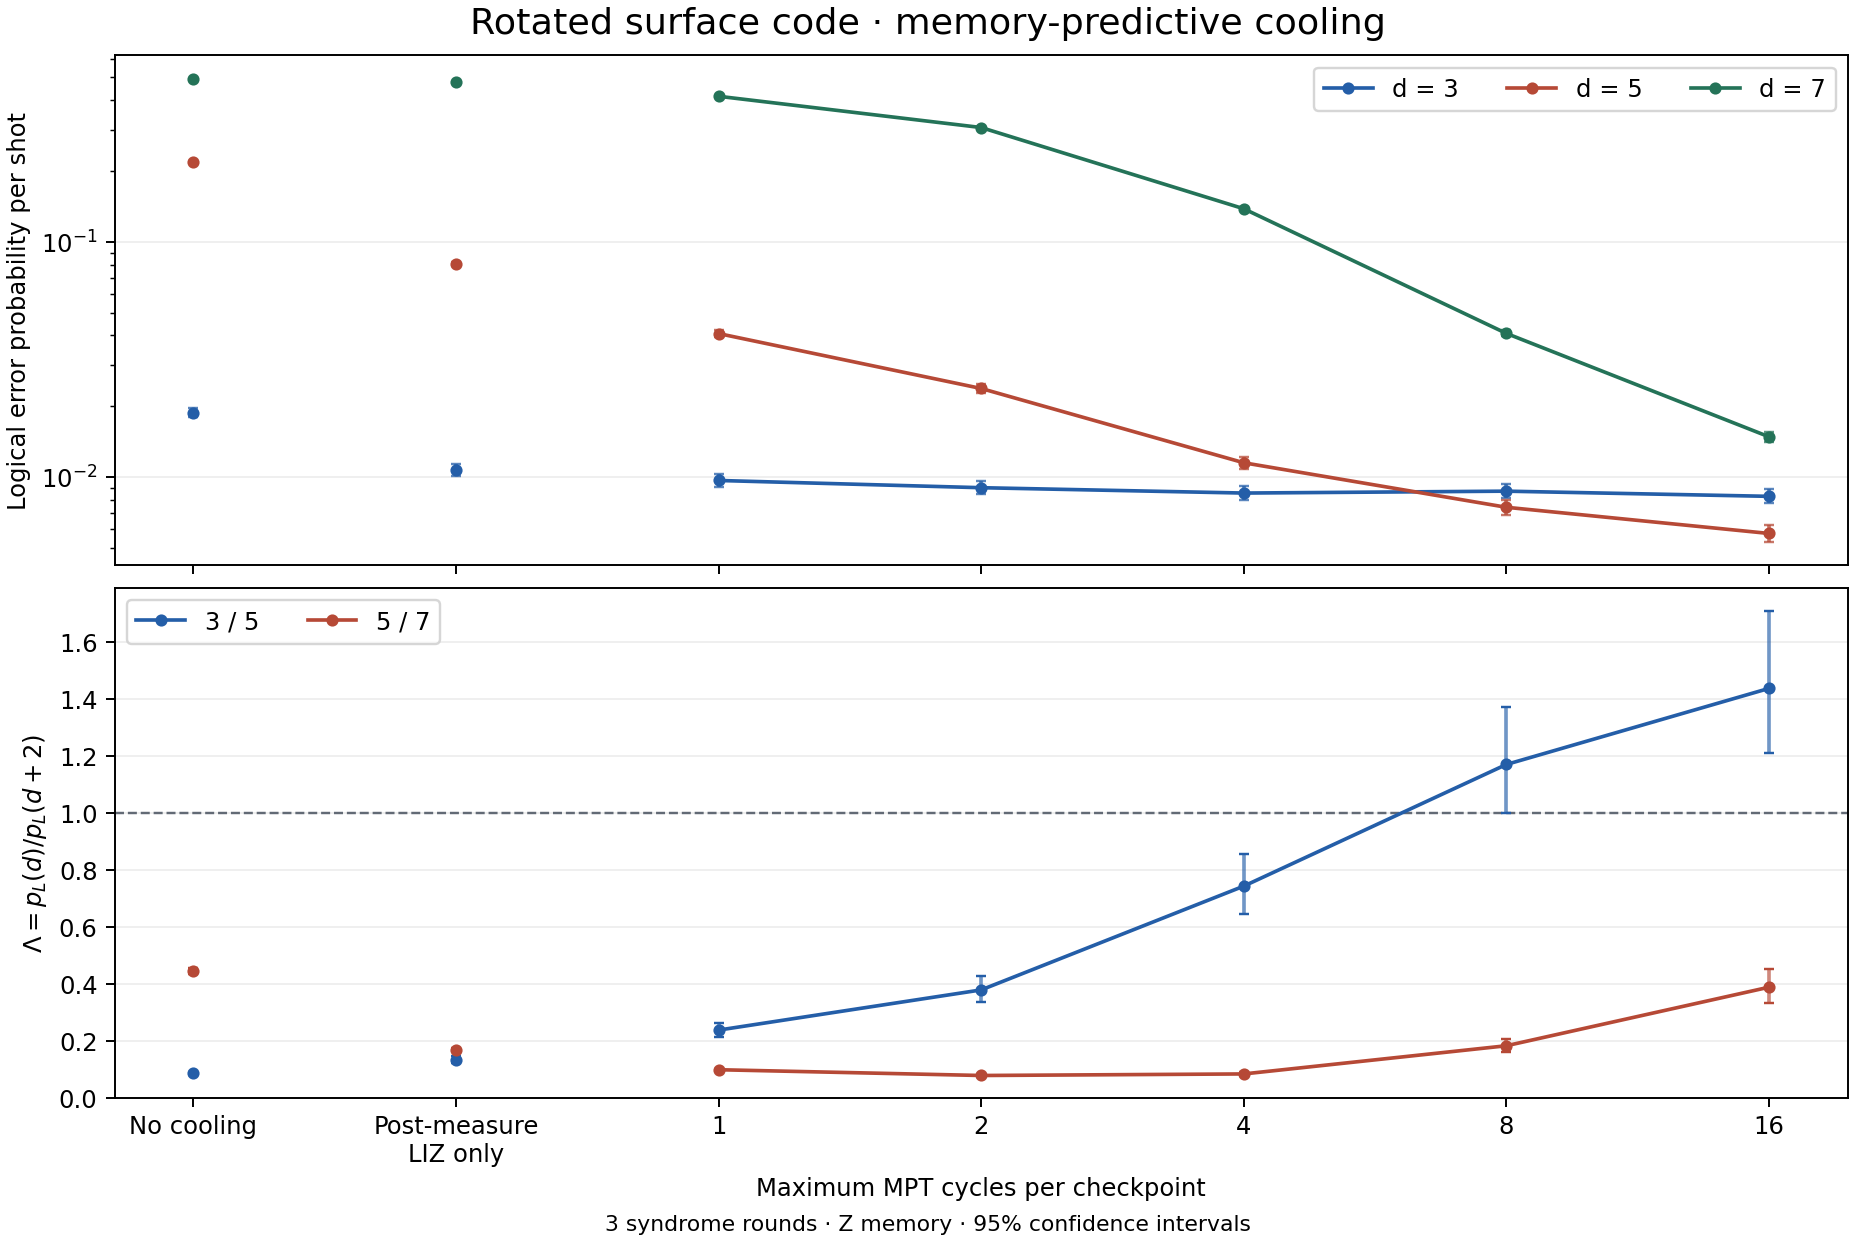

In [14]:
surface_cooling, surface_cooling_results = run_family("surface_cooling")
columns = [
    ("Distance", lambda row: row["distance"]),
    ("Condition", lambda row: row["condition"]),
    ("MPT iterations", lambda row: row["mpt_iterations"]),
    ("CoolOps", lambda row: row["cool_ops"]),
    ("Wall time (ms)", lambda row: f"{row['schedule_duration_us'] / 1000:.1f}"),
    ("Logical error [95% CI]", format_rate),
]
show_table(surface_cooling_results["rows"], columns)
show_figure(surface_cooling, "surface_cooling")

## Triangular color code · virtual phonon cap

The source is the `color-code-stim` `tri_optimal` circuit. Compilation preserves all source ions and the measurement record. The 15-component channel acts at the native MS gate. The concatenated MWPM decoder uses the selected memory detector sector and builds its DEM from the compiled noisy circuit.

Built color d=3 traces/d3/no_cooling
Built color d=5 traces/d5/no_cooling
Built color d=7 traces/d7/no_cooling
Built color d=9 traces/d9/no_cooling
Built color d=11 traces/d11/no_cooling


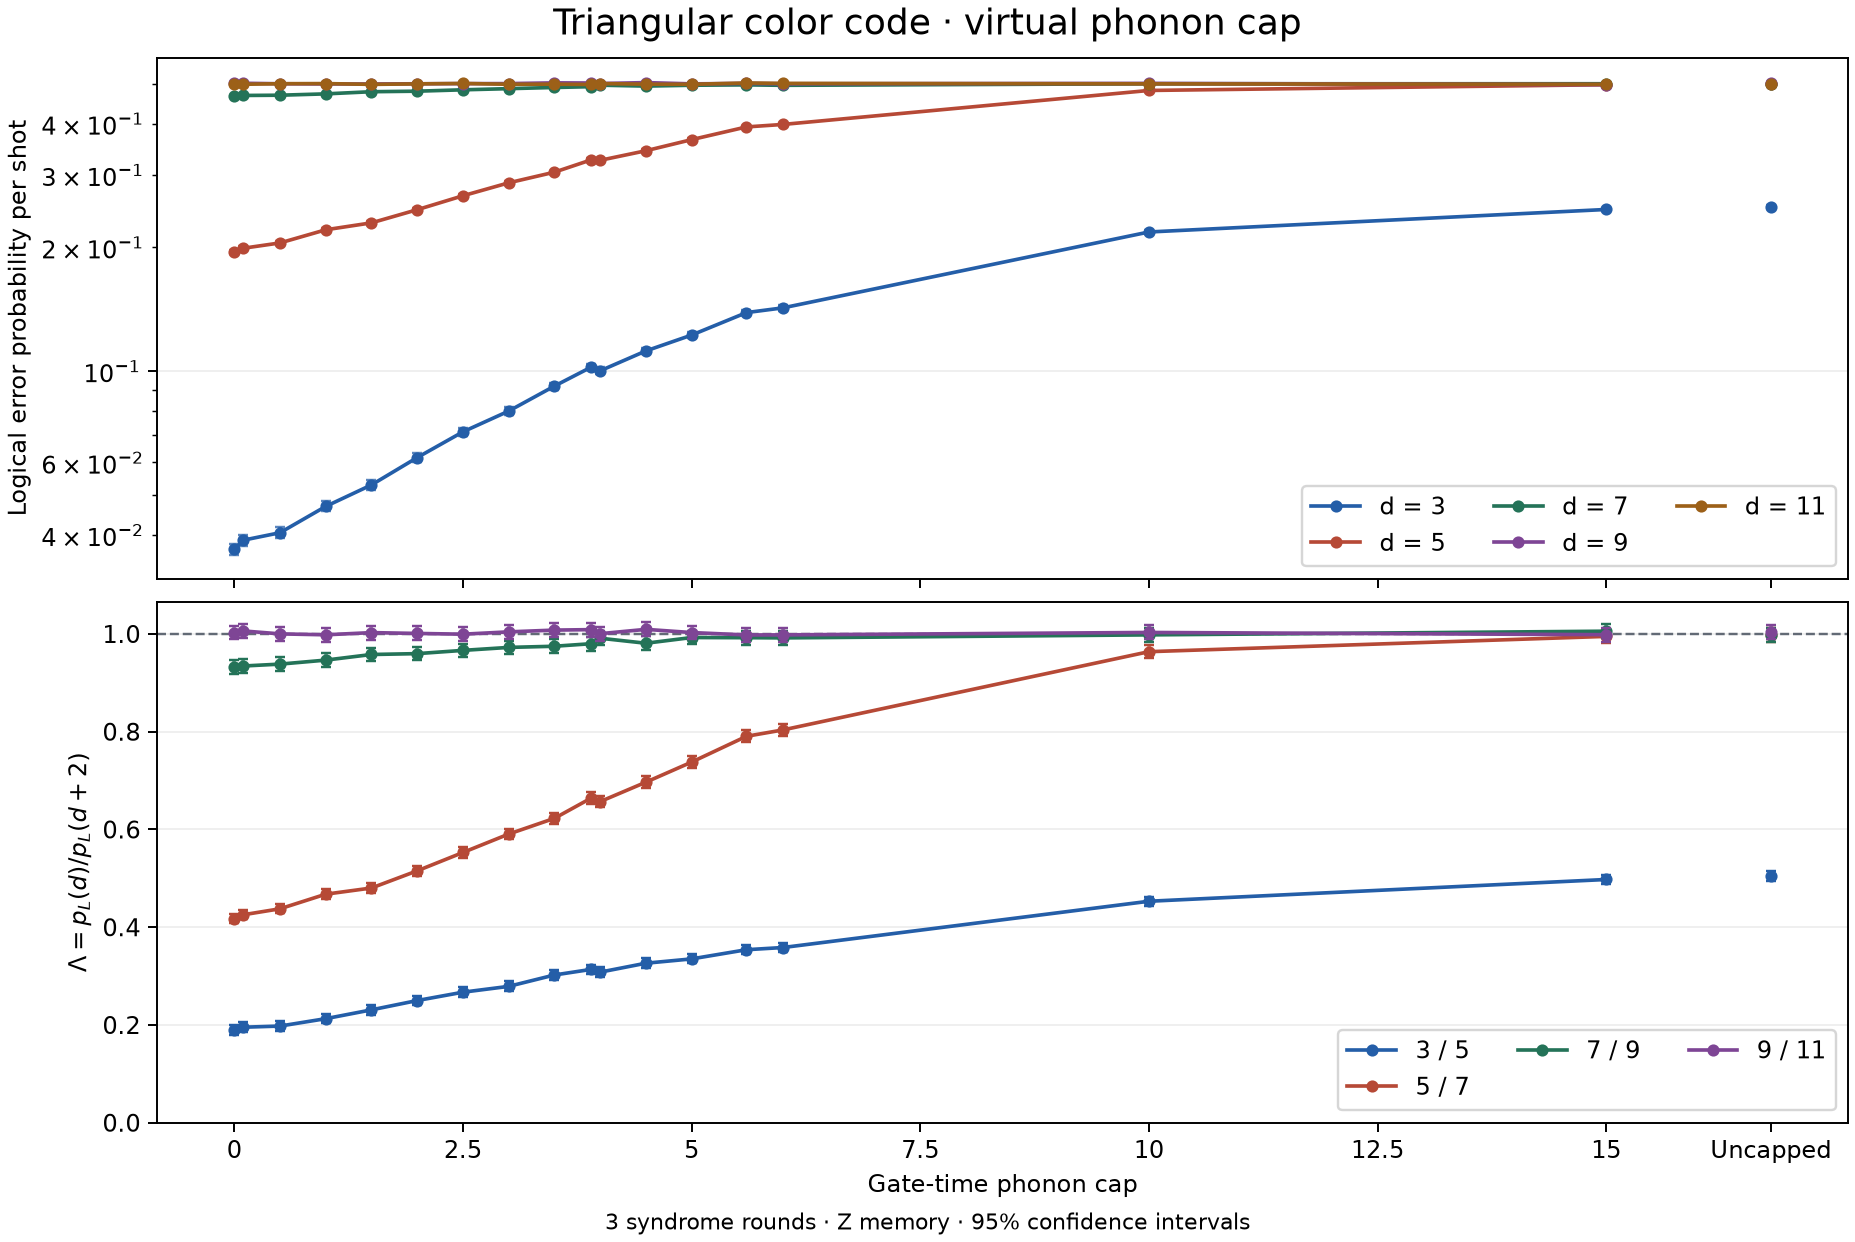

In [3]:
color_cap, color_cap_results = run_family("color_cap")
assert all(row["pruned_any_color"] == 0 for row in color_cap_results["rows"])
show_figure(color_cap, "color_cap")

## Triangular color code · maximum MPT cycles

All CNOT layers precede syndrome readout in each round. The audit records the next round's lookahead at the thermal reset. An episode before that reset cannot reduce the next round's initial occupations under this convention. A `policy_inactive` status means the budget points share the post-measurement LIZ-only physical circuit. Their sample estimates can vary across independent shot streams.

Built color d=3 traces/d3/no_cooling
Built color d=3 traces/d3/postmeasure_liz
Built color d=3 traces/d3/mpt/1
Built color d=3 traces/d3/mpt/16
Built color d=3 traces/d3/mpt/4
Built color d=3 traces/d3/mpt/8
Built color d=3 traces/d3/mpt/2
Built color d=5 traces/d5/no_cooling
Built color d=5 traces/d5/postmeasure_liz
Built color d=5 traces/d5/mpt/2
Built color d=5 traces/d5/mpt/1
Built color d=5 traces/d5/mpt/4
Built color d=5 traces/d5/mpt/16
Built color d=5 traces/d5/mpt/8
Built color d=7 traces/d7/postmeasure_liz
Built color d=7 traces/d7/no_cooling
Built color d=7 traces/d7/mpt/8
Built color d=7 traces/d7/mpt/1
Built color d=7 traces/d7/mpt/2
Built color d=7 traces/d7/mpt/4
Built color d=7 traces/d7/mpt/16


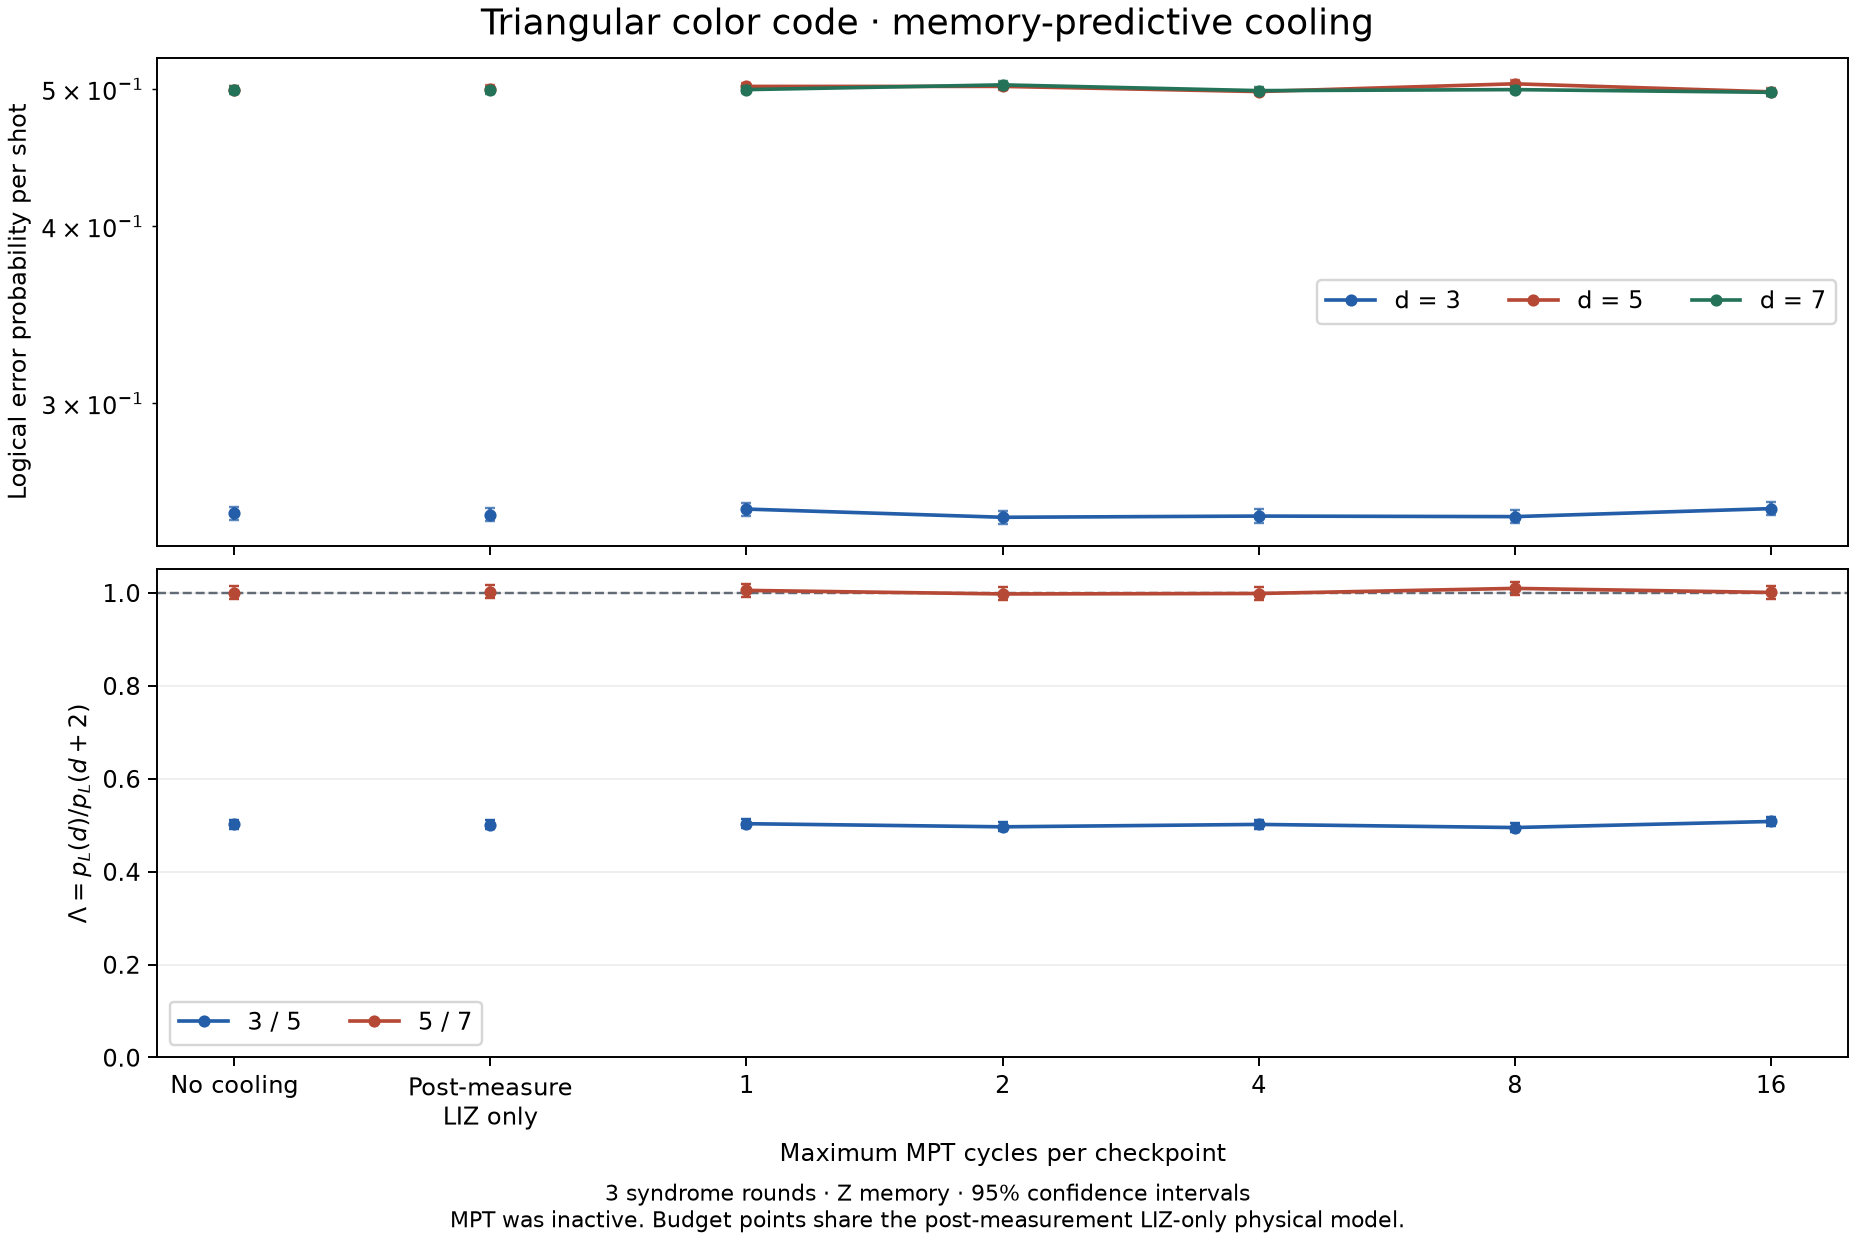

In [4]:
color_cooling, color_cooling_results = run_family("color_cooling")
for distance in sorted({row["distance"] for row in color_cooling_results["rows"]}):
    rows = [row for row in color_cooling_results["rows"] if row["distance"] == distance]
    mpt_rows = [row for row in rows if row["n_max"] is not None]
    control = next(row for row in rows if row["condition"] == "postmeasure_liz")
    assert all(row["policy_status"] == "policy_inactive" and row["eligible_checkpoints"] == 0
               and row["circuit_sha256"] == control["circuit_sha256"] for row in mpt_rows)
show_figure(color_cooling, "color_cooling")

## Regenerate figures and inspect the audit

The `plot` command reads saved statistics and writes PNG and PDF. Each output directory also contains `metrics.csv`, `ratios.csv`, the original and physical Stim circuits, decoder DEMs, trace and compiler settings, and the seed and integer failure count of every completed shard. Run the same simulation with `--resume` after an interruption. Use a fresh output directory when changing scientific settings.

In [7]:
for output in (surface_cap, surface_cooling, color_cap, color_cooling):
    cli("plot", "--out", output)

row = next(row for row in color_cooling_results["rows"] if row["condition"] == "mpt_1")
model = json.loads((color_cooling / row["model_path"]).read_text())
trace = json.loads((color_cooling / model["trace_path"] / "trace.json").read_text())
window = next(window for window in trace["round_traces"][0]["measurements"]
              if "across_reset_lookahead" in window)
print("Color d=3 MPT-1 cooling summary")
print(json.dumps(model["cooling"], indent=2))
print("First boundary lookahead")
lookahead = window["across_reset_lookahead"]
print(f"{len(lookahead['ms_gates'])} next-window MS gates. {lookahead['reason']}")

results/thermal_notebook_smoke/surface_cap/figures/surface_cap.png
results/thermal_notebook_smoke/surface_cap/figures/surface_cap.pdf


results/thermal_notebook_smoke/surface_cooling/figures/surface_cooling.png
results/thermal_notebook_smoke/surface_cooling/figures/surface_cooling.pdf


results/thermal_notebook_smoke/color_cap/figures/color_cap.png
results/thermal_notebook_smoke/color_cap/figures/color_cap.pdf


results/thermal_notebook_smoke/color_cooling/figures/color_cooling.png
results/thermal_notebook_smoke/color_cooling/figures/color_cooling.pdf
Color d=3 MPT-1 cooling summary
{
  "policy_status": "policy_inactive",
  "measurements": 25,
  "syndrome_measurements": 18,
  "compiled_data_readout_measurements": 7,
  "eligible_checkpoints": 0,
  "cross_reset_windows": 2,
  "trigger_activations": 0,
  "completed_loop_iterations": 0,
  "activated_checkpoints_with_episodes": 0,
  "transport_episodes": 0,
  "memory_visits": 0,
  "cool_ops": 18,
  "cooling_duration_us": 18000.0
}
First boundary lookahead
24 next-window MS gates. round reset discards any phonon reduction before the next measurement window
